# Range vs. take-off mass

For each MTOW, **1/3 is fuel** and **2/3 is empty mass**. The empty mass is reached by scaling every dry component in `base.json` by the same factor, so the CG positions stay as they are. The wing is sized for the stall speed at that MTOW, `run_pipeline(..., fuel_mass=...)` feeds the OpenVSP drag back, and the range follows from the fixed fuel.

Each case can override engine values of `base.json` (`ENGINES`): the 15 kg plane gets a 3.5 kW engine with 350 g/kWh.

Range includes the reserve (it is the distance the full tank covers); the dashed line is mission range + reserve from `base.json`. Grey: cruise power required at MTOW exceeds the engine power available at cruise altitude.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ardea_sizer as az
from ardea_sizer._constants import CRUISE_ALTITUDE, RHO_SL
from ardea_sizer.physics import get_isa_density

# MTOW [kg] -> engine overrides of base.json (p_max [kW], fuel_cons [kg/kWh])
ENGINES = {
    13.0: {"engine.p_max": 3.4, "engine.fuel_cons": 0.35},
    20.0: {"engine.p_max": 4.97, "engine.fuel_cons": 0.44},
}
FUEL_FRACTION = 1 / 3

base = az.load("../base.json")
TARGET_KM = (base.mission.range + base.mission.reserve) / 1000

In [2]:
def with_mtow(b, mtow):
    # base with every dry component scaled so the empty mass is (1 - FUEL_FRACTION) * mtow
    k = (1 - FUEL_FRACTION) * mtow / b.masses.empty
    return b.with_(**{f"masses.{name}.mass": k * p.mass for name, p in b.masses.dry()})


rows = []
for mtow, engine in ENGINES.items():
    fuel = FUEL_FRACTION * mtow
    b = with_mtow(base, mtow).with_(**engine)
    plane, _ = az.run_pipeline(b, fuel_mass=fuel, verbose=False)
    rows.append({
        "MTOW [kg]": float(plane.mtow),
        "empty [kg]": plane.masses.empty,
        "fuel [kg]": float(plane.fuel_mass),
        "wing area [m²]": float(plane.wing_area),
        "CD0": float(plane.c_d_0),
        "P max SL [kW]": b.engine.p_max,
        "SFC [g/kWh]": 1000 * b.engine.fuel_cons,
        "P cruise [kW]": float(plane.power_req) / 1000,
        "P avail. cruise [kW]": plane.power_available * get_isa_density(altitude=CRUISE_ALTITUDE) / RHO_SL,
        "range [km]": float(plane.range) / 1000,
    })

df = pd.DataFrame(rows)
df["power ok"] = df["P cruise [kW]"] <= df["P avail. cruise [kW]"]
df.round(3)

,MTOW [kg],empty [kg],fuel [kg],wing area [m²],CD0,P max SL [kW],SFC [g/kWh],P cruise [kW],P avail. cruise [kW],range [km],power ok
0,13.0,8.667,4.333,0.415,0.021,3.40,350.0,4.038,3.221,921.480,False
1,20.0,13.333,6.667,0.624,0.017,4.97,440.0,4.870,4.708,935.348,False


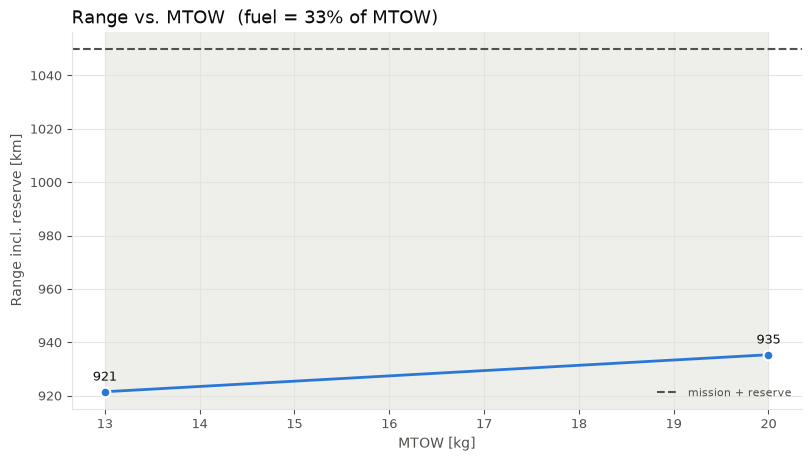

Finish


In [3]:
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = "#2a78d6"

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)

# grey band around points where cruise power exceeds P_max
x = df["MTOW [kg]"].to_numpy()
edges = np.concatenate(([x[0]], (x[1:] + x[:-1]) / 2, [x[-1]]))
for i, ok in enumerate(df["power ok"]):
    if not ok:
        ax.axvspan(edges[i], edges[i + 1], color=GRID, alpha=0.6, lw=0, zorder=0)

ax.axhline(TARGET_KM, color=INK_MUTED, lw=1.5, ls="--", zorder=1, label="mission + reserve")
ax.plot(x, df["range [km]"], "o-", color=SERIES, lw=2, ms=7, mec="white", mew=1.5, zorder=2)
for xi, r in zip(x, df["range [km]"]):
    ax.annotate(f"{r:.0f}", (xi, r), xytext=(0, 8), textcoords="offset points", ha="center",
                color=INK, fontsize=9)

ax.set_xlabel("MTOW [kg]", color=INK_MUTED)
ax.set_ylabel("Range incl. reserve [km]", color=INK_MUTED)
ax.set_title(f"Range vs. MTOW  (fuel = {FUEL_FRACTION:.0%} of MTOW)", color=INK, fontsize=13, loc="left")
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=INK_MUTED, labelsize=9)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_MUTED)
plt.show()
print("Finish")